# Research Question: #

### To what extent does Bear Blog's Trending feed reflect the ranking order predicted by its published ranking algorithm? 

***TEST 1** - reliable collection*

In [12]:

import requests
import feedparser
import pandas as pd
from datetime import datetime, timezone
from bs4 import BeautifulSoup
import re
import math

# Fetch Bear Blog's public Trending RSS feed
url = "https://bearblog.dev/discover/feed/"

headers = {
    "User-Agent": "INFO4617Research/1.0"
}

response = requests.get(url, headers=headers, timeout=20)
response.raise_for_status()

feed = feedparser.parse(response.content)

print("HTTP status:", response.status_code)
print("Feed title:", feed.feed.get("title"))
print("Posts collected:", len(feed.entries))
print("\nAvailable fields:")
print(feed.entries[0].keys())

print("\nFirst five posts:")
for position, post in enumerate(feed.entries[:5], start=1):
    print(
        position,
        "|", post.get("title"),
        "|", post.get("published"),
        "|", post.get("link")
    )


HTTP status: 200
Feed title: Bear Blog Trending Posts
Posts collected: 20

Available fields:
dict_keys(['id', 'guidislink', 'link', 'title', 'title_detail', 'links', 'published', 'published_parsed', 'updated', 'updated_parsed', 'content', 'summary'])

First five posts:
1 | My life without the algorithm | 2026-11-15T18:13:16.098397+00:00 | https://grazinggoats.bearblog.dev/my-life-without-the-algorithm/
2 | Did the 'AI doc' blow me off? | 2026-11-14T13:23:34.486084+00:00 | https://itsme.bearblog.dev/did-the-ai-doc-blow-me-off/
3 | The death you imagine | 2026-11-14T17:50:10.551707+00:00 | https://zuma9pt5.com/the-death-you-imagine/
4 | chronic illness and personal time | 2026-11-14T22:27:55.190535+00:00 | https://blog.avas.space/illness-me-time/
5 | An Open Letter to Apple: Enough Is Enough | 2026-11-15T19:01:28.056837+00:00 | https://rhyn0bytes.bearblog.dev/to-apple-enough-is-enough/


***TEST 2** - Upvotes on individual posts*

In [14]:

# Inspect the first five individual post pages for upvote information

for post in feed.entries[:5]:
    page = requests.get(
        post.link,
        headers=headers,
        timeout=20
    )

    soup = BeautifulSoup(page.text, "html.parser")
    page_text = soup.get_text(" ", strip=True)

    print("\nPOST:", post.title)
    print("HTTP status:", page.status_code)

    # Search page text and HTML for possible vote indicators
    matches = re.findall(
        r".{0,60}(?:upvote|upvotes|vote|votes|like|likes).{0,60}",
        page_text,
        flags=re.IGNORECASE
    )

    print("Possible vote text:", matches[:5])

    html_matches = re.findall(
        r".{0,80}(?:upvote|upvotes|vote_count|vote-count).{0,80}",
        page.text,
        flags=re.IGNORECASE
    )

    print("Possible vote HTML:", html_matches[:5])



POST: My life without the algorithm
HTTP status: 200
Possible vote text: ['a, social apps, Netflix or paid media subscriptions. I feel like I am watching more good quality tv and films because of it.']
Possible vote HTML: ['.upvote-button svg {\r', '.upvote-button::before {\r', '.upvote-button.upvoted::before,\r', '.upvote-button[style*="salmon"]::before {\r', '    .upvote-button {']

POST: Did the 'AI doc' blow me off?
HTTP status: 200
Possible vote text: [" the bottom of his class, because at least he graduated - unlike a LLM agent that simply scraped the contents of Grey's Anat"]
Possible vote HTML: ['    .upvote-button {', '    .upvote-button.upvoted {', '    .upvote-count {', '            <form id="upvote-form" action="/upvote/" method="post" style="display: inline">', '            class="upvote-button"']

POST: The death you imagine
HTTP status: 200
Possible vote text: [' The one common theme is that they didn’t think it would be like this. You will probably be cared for by unde

***Outcome** - .upvote-count element is not real. no actual value despite being present in page source.*

***TEST 2B** - looking for actual numerical value*

In [16]:

# Inspect the upvote elements on the first five posts

for post in feed.entries[:5]:
    page = requests.get(
        post.link,
        headers=headers,
        timeout=20
    )

    soup = BeautifulSoup(page.text, "html.parser")

    print("\nPOST:", post.title)
    print("HTTP status:", page.status_code)

    count_element = soup.select_one(".upvote-count")
    button_element = soup.select_one(".upvote-button")
    form_element = soup.select_one("#upvote-form")

    print("Upvote count element:", 
          count_element.get_text(strip=True) if count_element else "NOT FOUND")

    print("Upvote button:", 
          str(button_element)[:500] if button_element else "NOT FOUND")

    print("Upvote form:", 
          str(form_element)[:800] if form_element else "NOT FOUND")




POST: My life without the algorithm
HTTP status: 200
Upvote count element: 
Upvote button: <button aria-label="Toast this post" class="upvote-button" title="Toast this post">
<svg aria-hidden="true" class="css-i6dzq1" fill="none" height="24" stroke="currentColor" stroke-linecap="round" stroke-linejoin="round" stroke-width="2" viewbox="0 0 24 24" width="24" xmlns="http://www.w3.org/2000/svg">
<title>Toast this post</title>
<polyline points="17 11 12 6 7 11"></polyline>
<polyline points="17 18 12 13 7 18"></polyline>
</svg>
<small aria-hidden="true" class="upvote-count"> </small>
</butt
Upvote form: <form action="/upvote/" id="upvote-form" method="post" style="display: inline">
<small>
<input name="uid" type="hidden" value="NjjnwbGVhnESRmXumWsQ"/>
<input name="title" type="hidden" value="My life without the algorithm"/>
<input name="token" type="hidden" value="NjjnwbGVhnESRmXumWsQ"/>
<button aria-label="Toast this post" class="upvote-button" title="Toast this post">
<svg aria-hidden="tr

***Outcome:** Nope.*

***TEST 2C** - Vote count through javascript?*

In [18]:

# Inspect JavaScript references related to upvotes

post = feed.entries[0]

page = requests.get(
    post.link,
    headers=headers,
    timeout=20
)

soup = BeautifulSoup(page.text, "html.parser")

print("POST:", post.title)

for script in soup.find_all("script"):
    src = script.get("src")
    script_text = script.get_text()

    if src:
        print("\nExternal script:", src)

    if re.search(r"upvote|vote-count|upvote-count", script_text, re.I):
        print("\nRelevant inline JavaScript:")
        print(script_text[:3000])


POST: My life without the algorithm

Relevant inline JavaScript:

    const $upvoteButton = document.querySelector('.upvote-button');
    const $upvoteCount =  document.querySelector('.upvote-count')
    let upvoteToken = '';
    let upvoteTokenAt = Infinity;

    fetch('/upvote-info/NjjnwbGVhnESRmXumWsQ/').then(response => response.json()).then(data => {
        if ($upvoteCount) $upvoteCount.innerText = data.upvote_count;
        upvoteToken = data.token;
        upvoteTokenAt = Date.now();
        if (data.upvoted) {
            $upvoteButton.disabled = true
            $upvoteButton.style.color = "salmon"
            $upvoteButton.ariaLabel = "Toasted"
            $upvoteButton.title = "Toasted"
            $upvoteButton.querySelector('title').textContent = "Toasted"
        }
        if ($upvoteCount) $upvoteButton.ariaLabel += ` (${data.upvote_count})`

        document.addEventListener('touchmove', interaction, {once: true});
        document.addEventListener('mousemove', intera

***TEST 2D** - Retrieval*

In [19]:

# Test the public upvote-info endpoint

post = feed.entries[0]

page = requests.get(post.link, headers=headers, timeout=20)
soup = BeautifulSoup(page.text, "html.parser")

form = soup.select_one("#upvote-form")
uid = form.select_one('input[name="uid"]')["value"]

endpoint = f"https://{requests.utils.urlparse(post.link).netloc}/upvote-info/{uid}/"

vote_response = requests.get(
    endpoint,
    headers=headers,
    timeout=20
)

print("Post:", post.title)
print("Endpoint status:", vote_response.status_code)
print("Response:", vote_response.text)

if vote_response.ok:
    vote_data = vote_response.json()
    print("\nUpvote count:", vote_data.get("upvote_count"))
    print("Upvoted:", vote_data.get("upvoted"))
    print("Available fields:", vote_data.keys())


Post: My life without the algorithm
Endpoint status: 200
Response: {"upvoted": false, "upvote_count": 24, "token": "NjjnwbGVhnESRmXumWsQ:12ebce9576523746b70a53187abd613ed31482fce7ca937d748358d19bd36753:1xSnWE:R_nN4kJw604yTpPkOu-f1laBK8GTYB2ShTzAJ0_y8I8"}

Upvote count: 24
Upvoted: False
Available fields: dict_keys(['upvoted', 'upvote_count', 'token'])


***Outcome:** YAY! Algorithm audit possible BD*

***TEST 3** - Consistency check*

In [23]:

# Retrieve upvote counts for all 20 Trending posts

vote_results = []

for position, post in enumerate(feed.entries, start=1):
    page = requests.get(
        post.link,
        headers=headers,
        timeout=20
    )

    soup = BeautifulSoup(page.text, "html.parser")
    form = soup.select_one("#upvote-form")

    if not form:
        print("Missing upvote form:", post.title)
        continue

    uid_input = form.select_one('input[name="uid"]')
    uid = uid_input["value"]

    endpoint = (
        f"{requests.utils.urlparse(post.link).scheme}://"
        f"{requests.utils.urlparse(post.link).netloc}"
        f"/upvote-info/{uid}/"
    )

    result = requests.get(
        endpoint,
        headers=headers,
        timeout=20
    )

    try:
        data = result.json()
        count = data.get("upvote_count")
    except ValueError:
        count = None

    vote_results.append({
        "position": position,
        "title": post.title,
        "url": post.link,
        "upvotes": count,
        "status": result.status_code
    })

votes_df = pd.DataFrame(vote_results)

display(votes_df[["position", "title", "upvotes", "status"]])

print("\nPosts checked:", len(votes_df))
print("Counts successfully retrieved:", votes_df["upvotes"].notna().sum())
print("Missing counts:", votes_df["upvotes"].isna().sum())


,position,title,upvotes,status
0,1,My life without the algorithm,25,200
1,2,Did the 'AI doc' blow me off?,45,200
2,3,The death you imagine,30,200
3,4,chronic illness and personal time,21,200
4,5,An Open Letter to Apple: Enough Is Enough,10,200
5,6,10 things to blog about,11,200
6,7,it felt like we were the only people in the world,12,200
7,8,knowember,18,200
8,9,"All I wanted was to make a budget, and now I h...",10,200
9,10,Could you help me tweak the search results on ...,11,200



Posts checked: 20
Counts successfully retrieved: 20
Missing counts: 0


***TEST 4** - Refreshing*

In [25]:

# Refresh the Trending RSS feed

fresh_response = requests.get(
    "https://bearblog.dev/discover/feed/",
    headers=headers,
    timeout=20
)

fresh_response.raise_for_status()
fresh_feed = feedparser.parse(fresh_response.content)

print("Posts retrieved:", len(fresh_feed.entries))
print("\nLast five positions:")

for position, post in enumerate(fresh_feed.entries, start=1):
    if position >= 16:
        print(position, "|", post.title, "|", post.link)

print("\nIs weeknotes #72 now in the RSS feed?")
print(any("weeknotes-72" in post.link for post in fresh_feed.entries))


Posts retrieved: 20

Last five positions:
16 | Knowember in the world of Imelda's Paws | https://imeldaspaws.com/knowember-in-the-world-of-imeldas-paws/
17 | What I’ve learned from this Microsoft outage | https://futureperfect.bearblog.dev/what-ive-learned-from-this-microsoft-outage/
18 | Knowember 2026 | https://sleepyram.bearblog.dev/knowember-2026/
19 | We Heart Seattle Doesn't | https://cultnorthwest.com/we-heart-seattle-doesnt/
20 | weeknotes #72 | https://olu.online/weeknotes-72/

Is weeknotes #72 now in the RSS feed?
True


In [27]:

test_urls = {
    "Website-only: weeknotes #72":
        "https://olu.online/weeknotes-72/",
    "RSS-only: Easier To Be Good":
        "https://www.jenn.site/easier-to-be-good/"
}

for label, url in test_urls.items():
    page = requests.get(url, headers=headers, timeout=20)
    soup = BeautifulSoup(page.text, "html.parser")

    print("\n", label)
    print("Page URL:", page.url)
    print("Page title:", soup.title.get_text(strip=True) if soup.title else "None")

    form = soup.select_one("#upvote-form")

    if not form:
        print("Upvote form: NOT FOUND")
        continue

    uid_input = form.select_one('input[name="uid"]')
    uid = uid_input["value"]

    origin = requests.utils.urlparse(url)
    endpoint = f"{origin.scheme}://{origin.netloc}/upvote-info/{uid}/"

    result = requests.get(endpoint, headers=headers, timeout=20)

    print("Endpoint:", endpoint)
    print("Endpoint status:", result.status_code)
    print("Response:", result.text[:500])




 Website-only: weeknotes #72
Page URL: https://olu.online/weeknotes-72/
Page title: weeknotes #72 – Olu Online
Endpoint: https://olu.online/upvote-info/knmkVYMocadnMICfxJbp/
Endpoint status: 200
Response: {"upvoted": false, "upvote_count": 5, "token": "knmkVYMocadnMICfxJbp:1084c0d40f15687cb89175489eb1c1df4a002a9fd97d824082a1d7513e91b30b:1xSndI:mG7Q7Ago0wFvx2_cZc5P_fmA-R5wufAGIJXcK9YTGWc"}

 RSS-only: Easier To Be Good
Page URL: https://www.jenn.site/easier-to-be-good/
Page title: Easier To Be Good – Jenneral HQ 🌠
Endpoint: https://www.jenn.site/upvote-info/EBhqsQYFqnYVfgKkXsmV/
Endpoint status: 200
Response: {"upvoted": false, "upvote_count": 9, "token": "EBhqsQYFqnYVfgKkXsmV:1084c0d40f15687cb89175489eb1c1df4a002a9fd97d824082a1d7513e91b30b:1xSndI:n_AYczhOL0la83h9hTf0wr7mfJShgJ-Czg4yMWiPugk"}


***TEST 5** - Trending without Cloudflare block*

In [29]:

# Inspect the actual Trending page

trending_url = "https://bearblog.dev/discover/"

web_response = requests.get(
    trending_url,
    headers=headers,
    timeout=20
)

print("HTTP status:", web_response.status_code)
print("Page title:")

web_soup = BeautifulSoup(web_response.text, "html.parser")
print(web_soup.title.get_text(strip=True) if web_soup.title else "No title")

print("\nPage text preview:")
print(web_soup.get_text(" ", strip=True)[:1000])

print("\nPost links found:")
post_links = web_soup.select('a[href*="bearblog.dev"], a[href^="https://"]')

for link in post_links[:10]:
    print(link.get_text(" ", strip=True), "|", link.get("href"))


HTTP status: 403
Page title:
Just a moment...

Page text preview:
Just a moment... Enable JavaScript and cookies to continue

Post links found:


# NEW QUESTION: 

### To what extent does Bear Blog's published ranking formula predict the ordering of posts in its Trending RSS feed? ##

***TEST 1** - Prepare ranking*

In [30]:
# Prepare data for the ranking algorithm test

ranking_df = votes_df.copy()

ranking_df["published"] = [
    datetime(*post.published_parsed[:6], tzinfo=timezone.utc)
    for post in feed.entries
]

ranking_df["published"] = pd.to_datetime(ranking_df["published"], utc=True)

print("Posts:", len(ranking_df))
print("Missing upvote counts:", ranking_df["upvotes"].isna().sum())
print("Missing publication dates:", ranking_df["published"].isna().sum())

display(ranking_df[["position", "title", "upvotes", "published"]])

Posts: 20
Missing upvote counts: 0
Missing publication dates: 0


,position,title,upvotes,published
0,1,My life without the algorithm,25,2026-11-15 18:13:16+00:00
1,2,Did the 'AI doc' blow me off?,45,2026-11-14 13:23:34+00:00
2,3,The death you imagine,30,2026-11-14 17:50:10+00:00
3,4,chronic illness and personal time,21,2026-11-14 22:27:55+00:00
4,5,An Open Letter to Apple: Enough Is Enough,10,2026-11-15 19:01:28+00:00
5,6,10 things to blog about,11,2026-11-15 14:40:00+00:00
6,7,it felt like we were the only people in the world,12,2026-11-15 11:31:08+00:00
7,8,knowember,18,2026-11-14 22:07:00+00:00
8,9,"All I wanted was to make a budget, and now I h...",10,2026-11-15 16:51:00+00:00
9,10,Could you help me tweak the search results on ...,11,2026-11-15 10:21:00+00:00


***TEST 2** - Calculate predicted ranking*

In [33]:
# Calculate Bear Blog's published ranking score
import numpy as np

epoch = pd.Timestamp("2020-01-01", tz="UTC")
buoyancy = 3

ranking_df["seconds_since_epoch"] = (
    ranking_df["published"] - epoch
).dt.total_seconds()

ranking_df["predicted_score"] = (
    np.log10(ranking_df["upvotes"])
    + ranking_df["seconds_since_epoch"] / (buoyancy * 86400)
)

ranking_df["predicted_position"] = (
    ranking_df["predicted_score"]
    .rank(ascending=False, method="min")
    .astype(int)
)

ranking_df["rank_difference"] = (
    ranking_df["predicted_position"] - ranking_df["position"]
).abs()

display(
    ranking_df.sort_values("predicted_position")[
        ["predicted_position", "position", "title",
         "upvotes", "predicted_score", "rank_difference"]
    ]
)

,predicted_position,position,title,upvotes,predicted_score,rank_difference
0,1,1,My life without the algorithm,25,838.317678,0
1,2,2,Did the 'AI doc' blow me off?,45,838.172557,0
2,3,3,The death you imagine,30,838.058178,0
16,4,17,What I’ve learned from this Microsoft outage,102,837.993218,13
3,5,4,chronic illness and personal time,21,837.967570,1
4,6,5,An Open Letter to Apple: Enough Is Enough,10,837.930895,1
5,7,6,10 things to blog about,11,837.911763,1
6,8,7,it felt like we were the only people in the world,12,837.905832,1
8,9,9,"All I wanted was to make a budget, and now I h...",10,837.900694,0
7,10,8,knowember,18,837.895782,2


***TEST 3** - Quanitfy overall agreement*

In [34]:
# Summarize how closely predicted rankings match RSS rankings

exact_matches = (ranking_df["rank_difference"] == 0).sum()

mean_difference = ranking_df["rank_difference"].mean()
median_difference = ranking_df["rank_difference"].median()

spearman_correlation = ranking_df["position"].corr(
    ranking_df["predicted_position"],
    method="spearman"
)

print(f"Exact position matches: {exact_matches}/20")
print(f"Mean absolute rank difference: {mean_difference:.2f}")
print(f"Median absolute rank difference: {median_difference:.2f}")
print(f"Spearman rank correlation: {spearman_correlation:.3f}")

Exact position matches: 7/20
Mean absolute rank difference: 1.30
Median absolute rank difference: 1.00
Spearman rank correlation: 0.862


***Outcome:** Bear Blog's published ranking formula closely predicts the ordering of posts in its Trending RSS feed, but it does not reproduce the ordering perfectly.*

***TEST 4** - Required Figure*

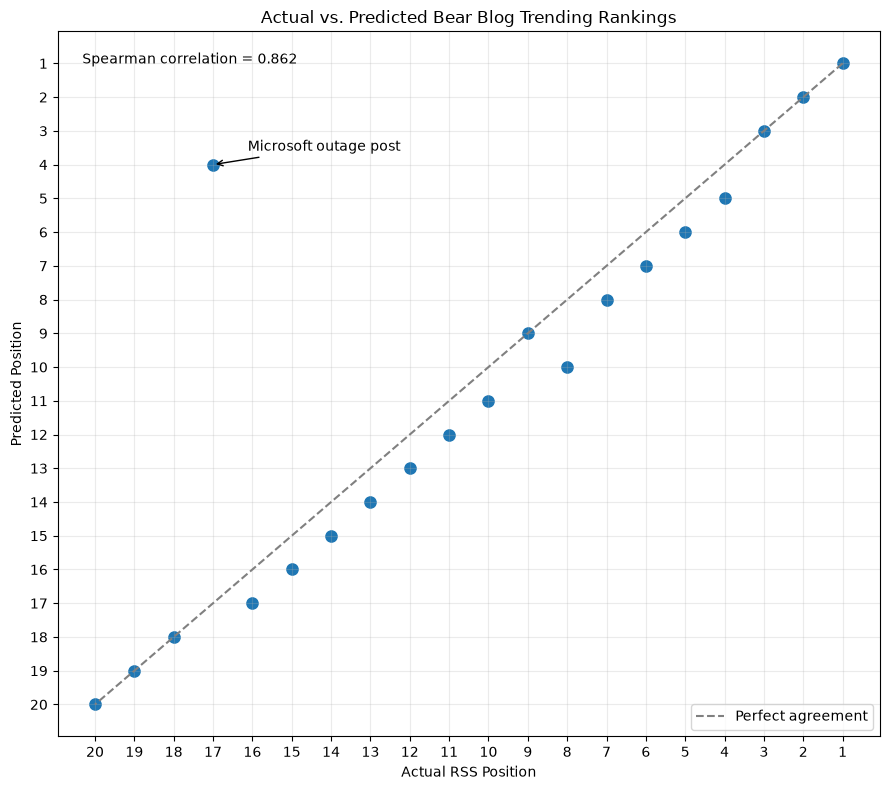

In [36]:
plt.figure(figsize=(9, 8))

plt.scatter(
    ranking_df["position"],
    ranking_df["predicted_position"],
    s=65
)

plt.plot([1, 20], [1, 20], linestyle="--", color="gray",
         label="Perfect agreement")

# Label the largest discrepancy
outlier = ranking_df.loc[
    ranking_df["rank_difference"].idxmax()
]

plt.annotate(
    "Microsoft outage post",
    (outlier["position"], outlier["predicted_position"]),
    xytext=(25, 10),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

plt.title("Actual vs. Predicted Bear Blog Trending Rankings")
plt.xlabel("Actual RSS Position")
plt.ylabel("Predicted Position")

plt.xticks(range(1, 21))
plt.yticks(range(1, 21))
plt.gca().invert_xaxis()
plt.gca().invert_yaxis()
plt.grid(alpha=0.25)

plt.text(
    0.03, 0.97,
    f"Spearman correlation = {spearman_correlation:.3f}",
    transform=plt.gca().transAxes,
    va="top"
)

plt.legend()
plt.tight_layout()
plt.savefig("ranking_comparison.png", dpi=300)
plt.show()

Figure 1. Actual RSS positions compared with positions predicted by Bear Blog's published ranking formula across 20 Trending posts. The strong positive Spearman correlation (ρ = 0.862) indicates substantial agreement, although several posts deviate from their predicted positions.

***Outcome:** The published ranking formula closely approximated the ordering of Bear Blog's Trending RSS feed. Across 20 posts, 7 appeared in exactly the predicted position, with a mean absolute rank difference of 1.30 positions. The Spearman rank correlation was 0.862, indicating a strong positive relationship between the predicted and actual rankings. However, one notable discrepancy was "What I've learned from this Microsoft outage," which ranked 17th in the RSS feed but 4th according to the formula. These findings suggest that the published formula is a strong predictor of RSS ordering, but may not fully explain how posts are ranked.*

In [38]:
ranking_df.to_csv("ranking_data.csv", index=False)